# Lumped capsule

By default the packed-bed model resolves the temperature across each capsule. With
`options={"storage element": "lumped"}` each capsule has a uniform temperature instead: one
enthalpy per capsule, heated through its surface. This is much cheaper, and accurate when
conduction inside a capsule is fast compared with heat transfer at its surface, that is when
the capsule's Biot number, `Bi = h R / k`, is small.

`"internal resistance": "Jeffreson"` puts part of the neglected internal resistance back,
through the heat transfer coefficient: `h_eff = h / (1 + Bi / 5)`. It only applies to a
lumped capsule.

Biot number, solid: 6.9
Biot number, liquid: 18.3


resolved: solve time 4.400 s
lumped: solve time 10.139 ms
lumped, Jeffreson: solve time 5.480 ms


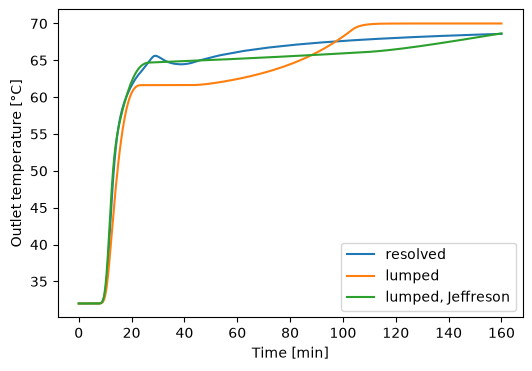

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes

variants = {
    "resolved": {},
    "lumped": {"storage element": "lumped"},
    "lumped, Jeffreson": {
        "storage element": "lumped",
        "internal resistance": "Jeffreson",
    },
}


def charge(options, conductivity=None):
    """The default charge (Nallusamy et al., 2007), optionally with other capsules"""
    model = pytes.PackedBedModel(options=options)
    parameter_values = model.default_parameter_values
    if conductivity is not None:
        for phase in ("solid", "liquid"):
            parameter_values[f"PCM {phase} phase conductivity [W.m-1.K-1]"] = (
                conductivity
            )
    t_end = 160 * 60
    return pybamm.Simulation(model, parameter_values=parameter_values).solve(
        [0, t_end], t_interp=np.linspace(0, t_end, 321)
    )


def compare(conductivity=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    for label, options in variants.items():
        solution = charge(options, conductivity)
        print(f"{label}: solve time {solution.solve_time}")
        ax.plot(
            solution["Time [min]"].entries,
            solution["Outlet temperature [degC]"].entries,
            label=label,
        )
    ax.set_xlabel("Time [min]")
    ax.set_ylabel("Outlet temperature [°C]")
    ax.legend()
    plt.show()


values = pytes.PackedBedModel().default_parameter_values
h = values["Heat transfer coefficient [W.m-2.K-1]"]
R = values["Capsule radius [m]"]
for phase in ("solid", "liquid"):
    k = values[f"PCM {phase} phase conductivity [W.m-1.K-1]"]
    print(f"Biot number, {phase}: {h * R / k:.1f}")
compare()

The paraffin capsules of the default set have Biot numbers of 7 to 18: far too large to
lump. The lumped capsule takes heat much faster than the resolved one, as nothing slows the
heat on its way into the capsule: its outlet stays colder while the PCM melts, and the bed
is fully charged after about 105 minutes instead of more than 160. Jeffreson's correction
follows the resolved outlet for the first half hour, but then charges too slowly: one
effective coefficient cannot follow a melting front moving into the capsule.

With capsules a hundred times more conductive (`k` = 40 W.m-1.K-1, `Bi` about 0.07), as
with a conductive filler, the three agree closely, and the lumped capsules solve over a
thousand times faster.

resolved: solve time 21.517 s
lumped: solve time 12.289 ms
lumped, Jeffreson: solve time 12.286 ms


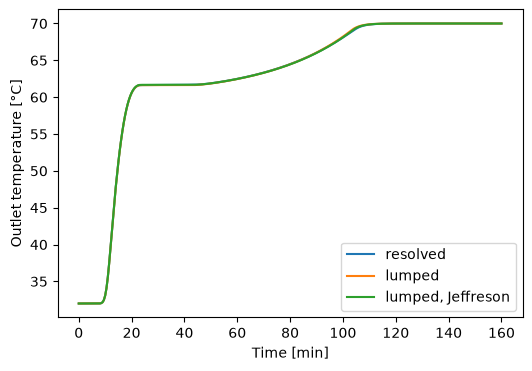

In [2]:
compare(conductivity=40)

Energy is conserved exactly whichever variant is used, and the lumped option combines with
`"storage along flow path": "averaged"` (one well-mixed capsule for the whole bed) and with
any heat transfer coefficient. On Schumann's benchmark, with sensible capsules, the lumped
bed is Schumann's model itself (see the validation notebook).